Output()

Физическая генерация заняла: 1.97 сек.
999

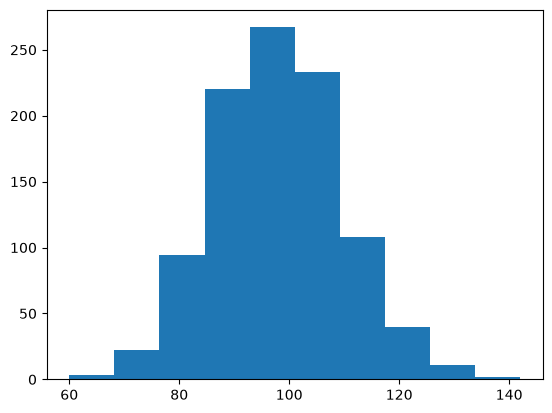

In [9]:
import random
import math
import time
######
import k3d
import numpy as np
######
import matplotlib.pyplot as mp

class Detector:
    def __init__(self,
                 R: float,
                 N: int,
                 r: float,
                 a: float
                ):
        self.R = R
        self.N = N
        self.r = r
        self.a = a
        self.attenuation_length = 8 # м

        # Чтобы равномерно расположить точки на сфере, сделаем их динамическими частицами с зарядами, которые отталкиваются друг от друга на сфере, и проведем короткую симуляцию. Ничего лучше не придумал
        phi_s = [random.uniform(0.0, 2.0 * math.pi) for _ in range(N-1)]
        cosTheta_s = [random.uniform(-1.0, 1.0) for _ in range(N-1)]
        coordinates = [[math.sqrt(max(0.0, 1.0 - c**2)) * math.cos(p), math.sqrt(max(0.0, 1.0 - c**2)) * math.sin(p), c] for p, c in zip(phi_s, cosTheta_s)]
        coordinates.append([0.0, 0.0, 1.0])
        ##### Для вывода анимации для отладки #######
        plot = k3d.plot(grid_visible=True, background_color=0xFFFFFF, menu_visibility=True, height=1000)
        
        ball = k3d.points(
            positions=[0.0, 0.0, 0.0],
            point_size=2.0,
            shader='3d',
            color=0xffffff,
            opacity=0.25
        )
        plot += ball

        FM_size = 2*self.r/self.R # рисуется на единичной сфере, так что размер ФЭУ нужно отскалировать
        pts_np = np.array(coordinates, dtype=np.float32)
        moving_points_video = k3d.points(
            positions=pts_np[:-1], 
            point_size=FM_size,
            color=0x1F77B4,
            shader="3d",
        )
        plot += moving_points_video

        plot += k3d.points(
            positions=pts_np[-1:],
            point_size=FM_size,
            color=0xD62728,
            shader="3d",
        )

        plot.display()
        ###############################
        charge = 10000
        dt = 1 / 1000
        drag = 5
        max_duration = 10.0
        precision = 1 / 10**6
        disturbance = 1
        velocities = [[0.0, 0.0, 0.0] for _ in range(N-1)]
        start_time = time.time()
        while disturbance > precision and (time.time() - start_time) < max_duration:
            disturbance = 0.0
            forces = [[0.0, 0.0, 0.0] for _ in range(N)]
            for i in range(N-1):
                for j in range(i+1, N):
                    distance = [ci - cj for ci, cj in zip(coordinates[i], coordinates[j])]
                    distance32 = ( distance[0]**2 + distance[1]**2 + distance[2]**2 + 1e-12 )**(3/2)
                    force = [charge * d / distance32 for d in distance]
                    forces[i] = [ff + f for ff, f in zip(forces[i], force)]
                    forces[j] = [ff - f for ff, f in zip(forces[j], force)]
                forces[i] = [ff - drag * v for ff, v in zip(forces[i], velocities[i])] # = ускорение
                velocities[i] = [v + f * dt for v, f in zip(velocities[i], forces[i])]
            for i in range(N-1):
                coordinates[i] = [c + v * dt for c, v in zip(coordinates[i], velocities[i])]
                distance32 = math.sqrt( coordinates[i][0]**2 + coordinates[i][1]**2 + coordinates[i][2]**2 ) # переиспользование переменной
                coordinates[i] = [c / distance32 for c in coordinates[i]] # координаты вернулись на сферу
                distance32 = coordinates[i][0] * velocities[i][0] + coordinates[i][1] * velocities[i][1] + coordinates[i][2] * velocities[i][2] # еще одно переиспользование
                velocities[i] = [v - c * distance32 for v, c in zip(velocities[i], coordinates[i])] # обнулили радиальную скорость
                distance32 = max([abs(v) for v in velocities[i]]) * dt # и еще одно переиспользование
                if distance32 > disturbance:
                    disturbance = distance32
            #################
            current_pts = np.array(coordinates[:-1], dtype=np.float32)
            moving_points_video.positions = current_pts
            time.sleep(1e-8)
            ##################
        self.coordinates = [[R * c for c in coordinates[i]] for i in range(N)]
        print(f"Физическая генерация заняла: {(time.time() - start_time):.2f} сек.")

    def if_belongs_to_FM(self,
                         theta: float,
                         phi: float
                        ):
        target_x = self.R * math.sin(theta) * math.cos(phi)
        target_y = self.R * math.sin(theta) * math.sin(phi)
        target_z = self.R * math.cos(theta)
        min_distance2 = float('inf')
        r2 = self.r**2
        for coord in self.coordinates:
            dx = coord[0] - target_x
            dy = coord[1] - target_y
            dz = coord[2] - target_z
            distance2 = dx**2 + dy**2 + dz**2
            if distance2 < min_distance2:
                min_distance2 = distance2
        if min_distance2 < r2:
            return True
        else:
            return False

    def is_captured(self,
                    x: float,
                    y: float,
                    z: float,
                    cosTheta: float,
                    phi: float,
                   ):
        sinTheta = math.sqrt(1.0 - cosTheta**2)
        nx = sinTheta * math.cos(phi)
        ny = sinTheta * math.sin(phi)
        nz = cosTheta
        A = nx**2 + ny**2 + nz**2
        B = 2 * (x*nx + y*ny + z*nz)
        C = x**2 + y**2 + z**2 - self.R**2
        D = B**2 - 4 * A * C
        root_plus = (-B + math.sqrt(D)) / (2 * A)
        survival_probability = math.exp(-root_plus / self.attenuation_length)
        if random.uniform(0.0, 1.0) < survival_probability:
            X = x + root_plus * nx
            Y = y + root_plus * ny
            Z = z + root_plus * nz
            theta = math.acos(max(-1.0, min(1.0, Z / self.R)))
            phi = math.atan2(Y, X)
            return self.if_belongs_to_FM(theta, phi)
        else:
            return False

    def number_of_photoelectrons(self):
        return np.random.poisson(self.a)

class Source:
    def __init__(self,
                 Y: float
                ):
        self.Y = Y
        self.portion = 100

    def generate_photon_directions(self,
                                   E: float # в МэВ
                                  ):
        l = E * self.Y
        N = np.random.poisson(l)
        N_full = N // self.portion
        N_rest = N % self.portion
        for _ in range(N_full):
            phi_s = np.random.uniform(0.0, 2.0 * math.pi, size=self.portion)
            cosTheta_s = np.random.uniform(-1.0, 1.0, size=self.portion)
            yield tuple(zip(cosTheta_s, phi_s))
        if N_rest > 0:
            phi_s = np.random.uniform(0.0, 2.0 * math.pi, size=N_rest)
            cosTheta_s = np.random.uniform(-1.0, 1.0, size=N_rest)
            yield tuple(zip(cosTheta_s, phi_s))

Det1 = Detector(2, 40, 0.1, 0.5)
Source1 = Source(1e4)
Source_coordinate = (0.0, 0.0, 0.0)
N_events = 1000

def experiment(E):
    Qs = []
    for i in range(N_events):
        photon_directions_generator = Source1.generate_photon_directions(E)
        Q = 0
        for ds in photon_directions_generator:
            for d in ds:
                if Det1.is_captured(*Source_coordinate, *d):
                    Q += Det1.number_of_photoelectrons()
        Qs.append(Q)
        print(f"\r{i}", end="")
    mp.hist(Qs)
    mp.show()

experiment(1)

999

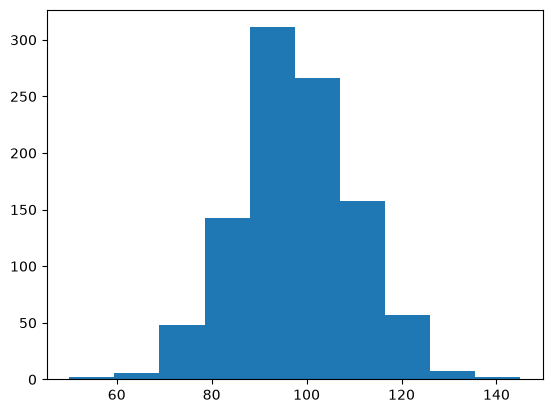

In [11]:
Source_coordinate = (0.0, 0.0, 0.5)
experiment(1)

999

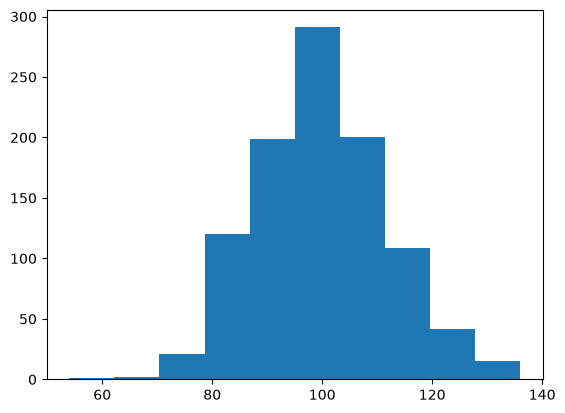

In [12]:
Source_coordinate = (0.0, 0.0, 1.0)
experiment(1)

999

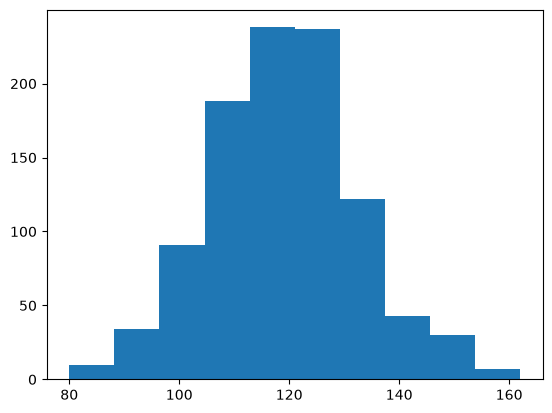

In [13]:
Source_coordinate = (0.0, 0.0, 1.5)
experiment(1)

999

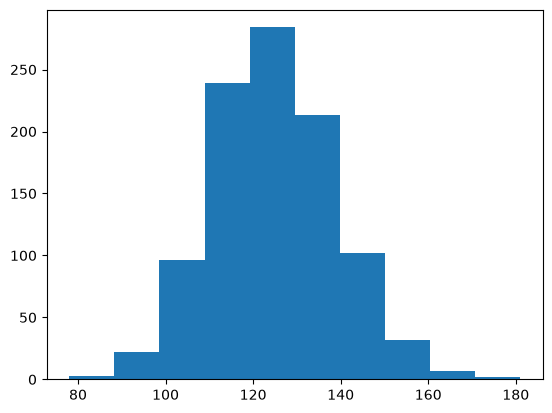

In [16]:
Det1.attenuation_length = float('inf')
Source_coordinate = (0.0, 0.0, 0.0)
experiment(1)

999

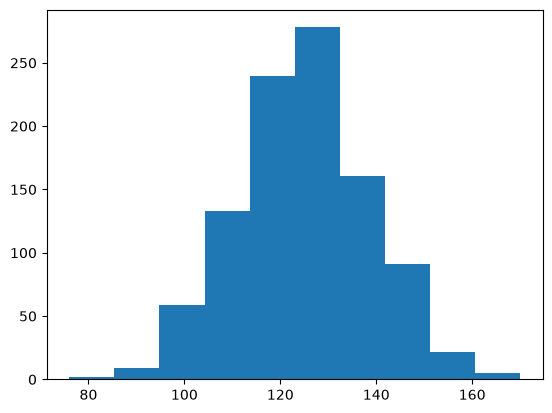

In [17]:
Source_coordinate = (0.0, 0.0, 0.5)
experiment(1)

999

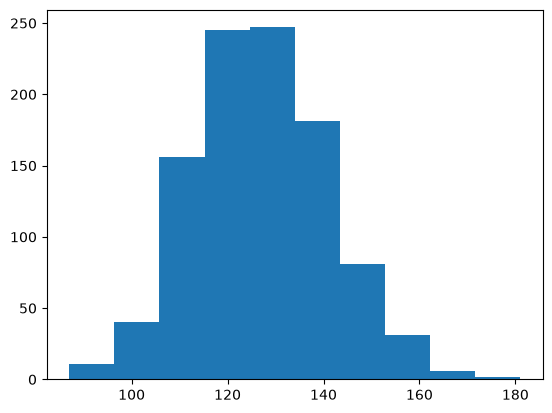

In [18]:
Source_coordinate = (0.0, 0.0, 1.0)
experiment(1)

999

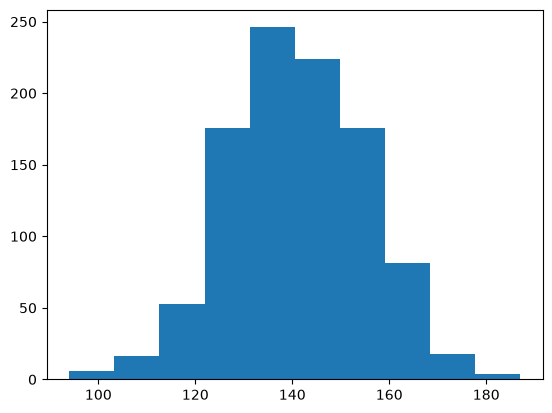

In [19]:
Source_coordinate = (0.0, 0.0, 1.5)
experiment(1)

In [20]:
# Как мы видим, отклик в случае затухания меньше, чем без него. Как и должно быть